# Model Interpretability

A model that predicts well is not automatically trustworthy. Interpretability helps us answer:

- Which features drive predictions globally?
- Why did the model make this specific prediction?
- Is the model relying on a spurious shortcut?
- What would change the prediction?

This notebook covers model-specific and model-agnostic methods:

- linear-model coefficients,
- tree feature importance (impurity),
- permutation importance,
- partial dependence plots,
- an introduction to SHAP and LIME.

## Learning objectives

1. Distinguish global from local explanations.
2. Read linear coefficients as effects on the log-odds.
3. Use permutation importance and explain why it is more reliable than impurity importance.
4. Interpret partial dependence plots and their limits.
5. Recognise when an explanation can be misleading.

## 1. Concepts

### Intrinsic vs post-hoc

- **Intrinsic**: the model is interpretable by design (linear regression, shallow tree).
- **Post-hoc**: explain a trained model after the fact (permutation importance, PDP, SHAP, LIME).

### Global vs local

- **Global**: overall behaviour across the dataset.
- **Local**: one prediction for one sample.

### Feature importance is not causality

Importance tells you what the model uses, not what causes the outcome. Correlated features can share
importance, and a model can exploit a confounding variable.

### Permutation importance

Shuffle one feature and measure how much the model's score drops. A large drop means the model relies
on that feature. Repeat several times to get a distribution.

### Partial dependence

Shows the average model prediction as one feature changes, holding other features fixed. It can be
misleading when features are correlated and the model extrapolates to unrealistic combinations.

### SHAP and LIME

- **SHAP** assigns each feature a contribution based on cooperative game theory. It provides local
  explanations with additive guarantees and can be aggregated globally.
- **LIME** fits a simple local surrogate around a prediction. It is fast but can be unstable.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Train an interpretable linear model and a random forest

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
logistic.fit(X_train, y_train)

forest = RandomForestClassifier(
    n_estimators=400, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1
)
forest.fit(X_train, y_train)

print("Logistic accuracy:", round(logistic.score(X_test, y_test), 4))
print("Random forest accuracy:", round(forest.score(X_test, y_test), 4))

Logistic accuracy: 0.986
Random forest accuracy: 0.958


## 4. Linear coefficients

For logistic regression, a coefficient is the change in log-odds for a one-unit increase in a scaled
feature. Exponentiating gives an odds ratio. This is a global, model-specific explanation.

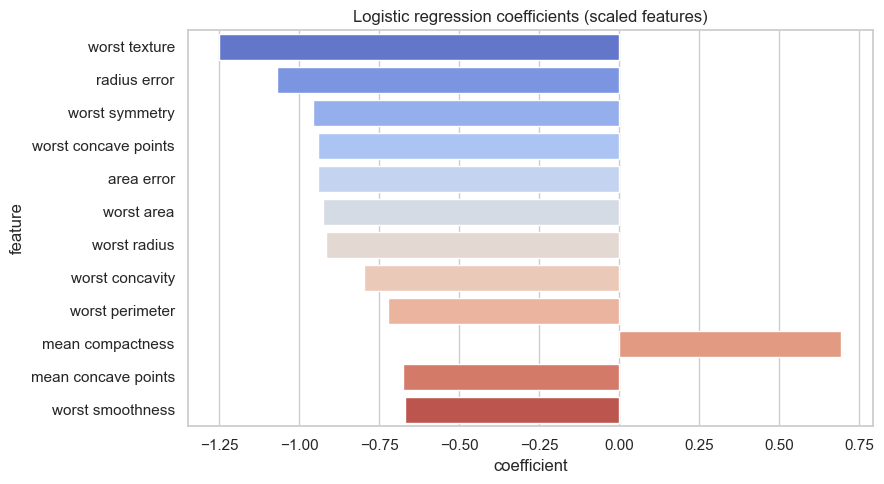

,feature,coefficient,odds_ratio
21,worst texture,-1.250,0.286
10,radius error,-1.070,0.343
28,worst symmetry,-0.957,0.384
27,worst concave points,-0.942,0.390
13,area error,-0.941,0.390
23,worst area,-0.926,0.396
20,worst radius,-0.917,0.400
26,worst concavity,-0.797,0.451
22,worst perimeter,-0.721,0.486
5,mean compactness,0.694,2.002


In [3]:
coefficients = pd.DataFrame({
    "feature": X.columns,
    "coefficient": logistic.named_steps["model"].coef_[0],
})
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients["abs_coefficient"] = coefficients["coefficient"].abs()

top = coefficients.sort_values("abs_coefficient", ascending=False).head(12)
plt.figure(figsize=(9, 5))
sns.barplot(data=top, x="coefficient", y="feature", palette="coolwarm")
plt.title("Logistic regression coefficients (scaled features)")
plt.tight_layout()
plt.show()
top[["feature", "coefficient", "odds_ratio"]].round(3)

## 5. Impurity-based feature importance

Tree ensembles report how much each feature reduces impurity. It is fast but biased toward
high-cardinality and correlated features, and it is computed on training data.

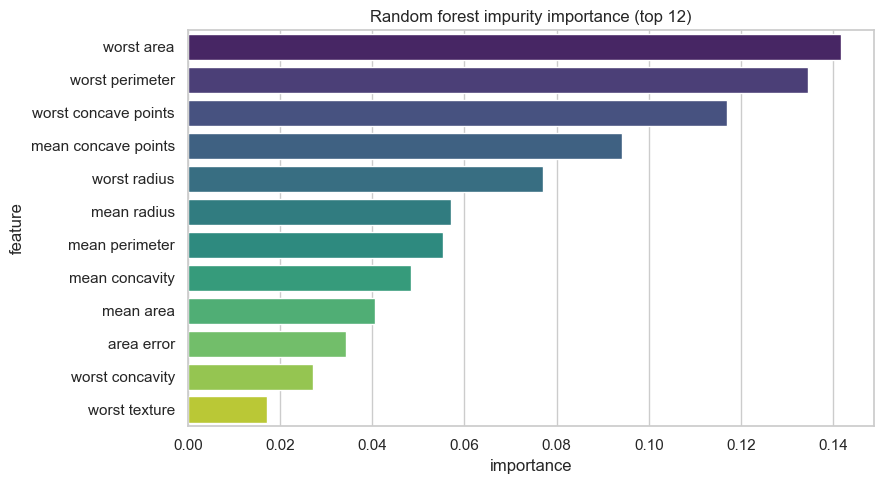

In [4]:
impurity = pd.DataFrame({
    "feature": X.columns,
    "importance": forest.feature_importances_,
}).sort_values("importance", ascending=False).head(12)

plt.figure(figsize=(9, 5))
sns.barplot(data=impurity, x="importance", y="feature", palette="viridis")
plt.title("Random forest impurity importance (top 12)")
plt.tight_layout()
plt.show()

## 6. Permutation importance

Permutation importance measures the drop in test performance when a feature is randomly shuffled.
It is model-agnostic and computed on held-out data, which makes it more trustworthy for model
selection - though still not causal.

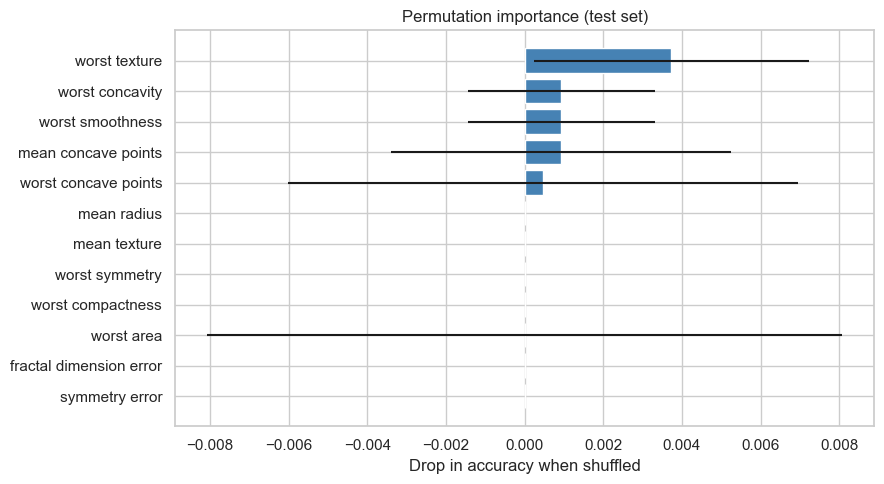

,feature,mean_importance,std
21,worst texture,0.0037,0.0035
26,worst concavity,0.0009,0.0024
24,worst smoothness,0.0009,0.0024
7,mean concave points,0.0009,0.0043
27,worst concave points,0.0005,0.0065
0,mean radius,0.0000,0.0000
1,mean texture,0.0000,0.0000
28,worst symmetry,0.0000,0.0000
25,worst compactness,0.0000,0.0000
23,worst area,0.0000,0.0081


In [5]:
perm = permutation_importance(
    forest, X_test, y_test,
    n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1, scoring="accuracy",
)

perm_df = pd.DataFrame({
    "feature": X.columns,
    "mean_importance": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("mean_importance", ascending=False).head(12)

plt.figure(figsize=(9, 5))
plt.barh(perm_df["feature"][::-1], perm_df["mean_importance"][::-1],
         xerr=perm_df["std"][::-1], color="steelblue")
plt.xlabel("Drop in accuracy when shuffled")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.show()
perm_df.round(4)

### Correlated features

If two features carry the same information, shuffling one may barely hurt performance because the
other still provides it. Always inspect the correlation structure before concluding that a feature
is unimportant.

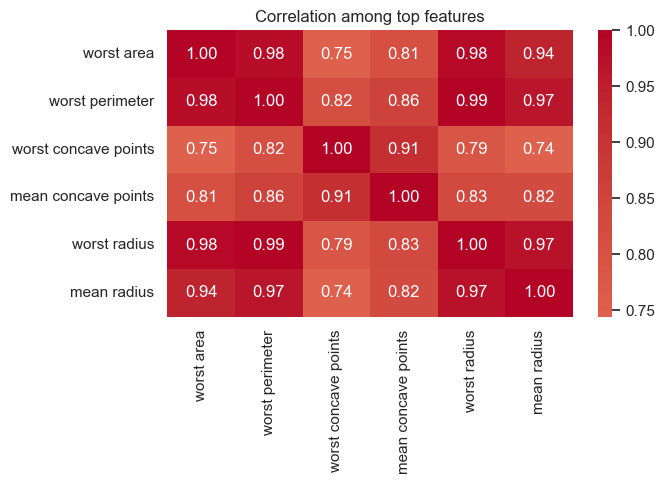

In [6]:
correlation = X.corr().abs()
top_features = impurity["feature"].head(6).tolist()

plt.figure(figsize=(7, 5))
sns.heatmap(X[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation among top features")
plt.tight_layout()
plt.show()

## 7. Partial dependence

Partial dependence shows the average predicted probability as one feature varies. It answers
"what does the model predict across the range of this feature?" - not "what happens if we intervene?".

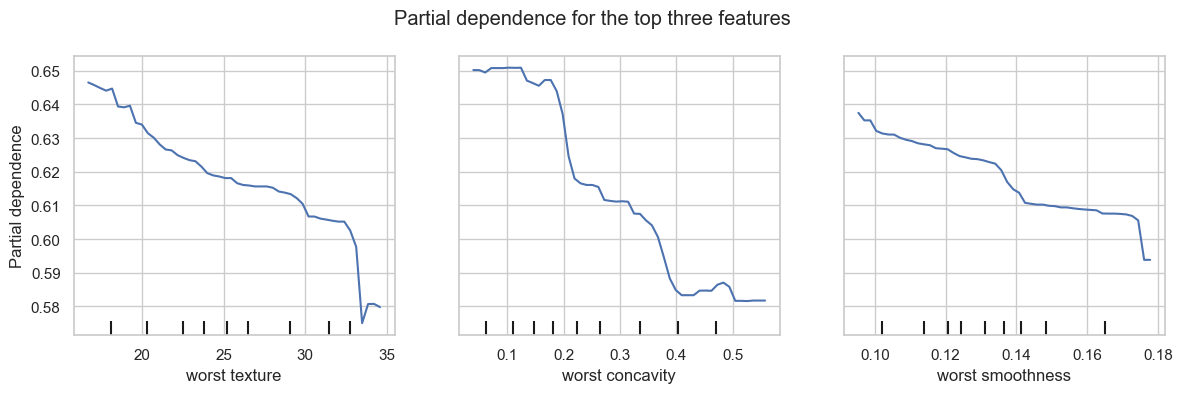

In [7]:
top_three = perm_df["feature"].head(3).tolist()

fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    forest, X_test, top_three, kind="average", ax=ax, grid_resolution=50
)
plt.suptitle("Partial dependence for the top three features")
plt.tight_layout()
plt.show()

### Two-feature partial dependence

A two-dimensional PDP can reveal interactions, but it also makes extrapolation easier to hide.

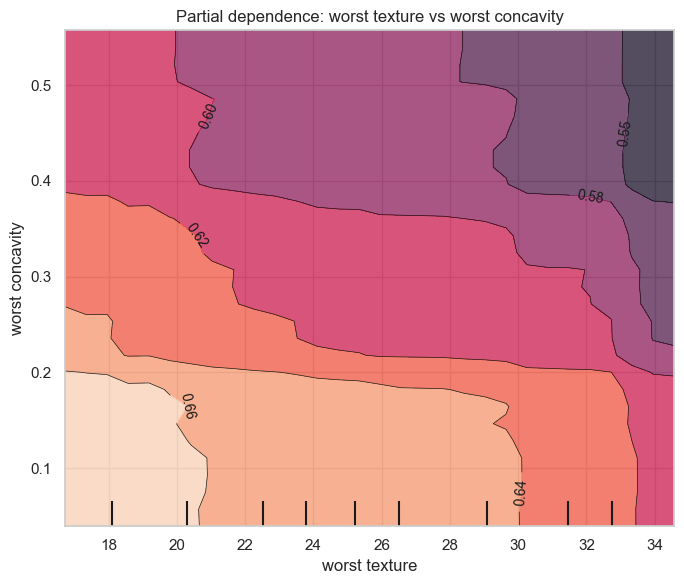

In [8]:
if len(top_three) >= 2:
    fig, ax = plt.subplots(figsize=(7, 6))
    PartialDependenceDisplay.from_estimator(
        forest, X_test, [(top_three[0], top_three[1])], kind="average", ax=ax, grid_resolution=30
    )
    plt.title(f"Partial dependence: {top_three[0]} vs {top_three[1]}")
    plt.tight_layout()
    plt.show()

## 8. Local explanations with SHAP and LIME

The code below is intentionally not executed because SHAP and LIME are optional dependencies. Install
them with:

```bash
pip install shap lime
```

A minimal SHAP example for a tree model:

```python
import shap

explainer = shap.TreeExplainer(forest)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)
shap.plots.waterfall(shap_values[0])
```

A minimal LIME example:

```python
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(
    X_train.to_numpy(),
    feature_names=X.columns.tolist(),
    class_names=data.target_names.tolist(),
    discretize_continuous=True,
)
explanation = explainer.explain_instance(X_test.iloc[0].to_numpy(), forest.predict_proba)
explanation.show_in_notebook()
```

SHAP values are additive feature contributions. They can explain one prediction or be aggregated
into global summary plots. LIME fits a local linear surrogate and is useful for quick checks, but its
explanations can vary between runs.

## 9. Pitfalls

- **Correlation is not causation**: importance is about model behaviour, not real-world effects.
- **Extrapolation**: PDP can evaluate the model on feature combinations that never occur.
- **Correlated features**: importance can be split or hidden.
- **Data leakage**: a model may look great because it uses a feature that encodes the target.
- **Explanation instability**: small data or model changes can change local explanations.
- **Human factors**: a convincing explanation is not necessarily a correct one.

## Key takeaways

- Use linear coefficients and shallow trees when intrinsic interpretability matters.
- Prefer permutation importance on held-out data over impurity importance.
- PDP is useful for global trends but sensitive to correlation and extrapolation.
- SHAP and LIME provide local explanations; use them with domain review.
- Interpretability supports trust and debugging, but it does not prove causality.

## Exercises

1. Compare permutation importance computed on train vs test data.
2. Add a duplicate of an important feature and observe how importance splits.
3. Plot a PDP for a feature with a narrow range and discuss extrapolation.
4. Install SHAP and generate a summary plot for the random forest.
5. Find a sample that the model misclassifies and explain it with LIME.
6. Write a short model card describing intended use, limitations, and evaluation data.